# End-to-end Rust inference pipeline

This notebook demonstrates the complete Rust workflow:

1. Load raw count data from an h5ad file (Python AnnData)
2. Build a `SearchData` object via the GIL-free Rust path (`searchdata_from_h5ad`)
3. Run inference with the Rust L-BFGS-B optimizer
4. Write fitted parameters back into the original AnnData and save as h5ad

A second section repeats the same steps **with gene length correction**, showing
how `log_lengths` in `adata.var` feeds into the Poisson sequencing model.

**Dataset**: `processed_pbmc_10k_raw.h5ad` — 10 997 cells × 36 601 genes  
**Model**: Bursty + Poisson  
**Gene count**: 100 top-expressed genes (for speed)

## Setup

In [1]:
# Work from the repository root (data in example_h5ad/, figures in figures/)
# and import monod from src/ when running against a checkout.
import os, sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, 'setup.cfg')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
if os.path.isdir(os.path.join(_root, 'src')) and os.path.join(_root, 'src') not in sys.path:
    sys.path.insert(0, os.path.join(_root, 'src'))


In [2]:
import sys, os, time
import numpy as np
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt


from monod.cme_toolbox import CMEModel
from monod.inference import InferenceParameters, searchdata_from_adata
import monod_core as _mc

print(f'monod_core: {_mc.__file__}')

H5AD_PATH = 'example_h5ad/processed_pbmc_10k_raw.h5ad'
N_GENES   = 100
MODEL     = CMEModel('Bursty', 'Poisson')
LAYER_NAMES = ['unspliced', 'spliced']

# Optimizer settings. 200 L-BFGS-B iterations gives good convergence;
# a 3×4 grid (12 sampling-rate points) keeps the demo fast.
GRADIENT_PARAMS = {
    'max_iterations': 200,
    'init_pattern':   'moments',
    'num_restarts':   1,
    'num_gene_cores': -1,        # -1 → all available cores via rayon
    'use_rust_lbfgsb': True,
}
GRIDSIZE = [3, 4]

monod_core: /home/coakes/miniconda3/envs/monod/lib/python3.11/site-packages/monod_core/__init__.py


## Select genes and load AnnData

We load the full AnnData once in Python to select genes.  The heavy work
(histogram extraction, moment computation) is delegated to Rust in the next step.

In [3]:
adata = ad.read_h5ad(H5AD_PATH)
print(adata)

# Select the N_GENES most-expressed genes by mean spliced count.
s = adata.layers['spliced']
means = np.asarray(s.mean(axis=0)).ravel() if sp.issparse(s) else s.mean(axis=0)
top_idx   = np.argsort(means)[::-1][:N_GENES]
GENE_NAMES = list(adata.var_names[top_idx])

print(f'\nSelected {len(GENE_NAMES)} genes.  First 5: {GENE_NAMES[:5]}')

AnnData object with n_obs × n_vars = 10997 × 36601
    obs: 'barcode', 'obs_names', 'subclass_label'
    var: 'gene_name', 'var_names'
    layers: 'matrix', 'spliced', 'unspliced'

Selected 100 genes.  First 5: ['35335', '35341', '35337', '35340', '1426']


---
## Part 1 — Rust pipeline without gene lengths

`searchdata_from_h5ad` reads the h5ad, filters to the requested genes, and builds
unique histograms and moments entirely inside a single GIL-free Rust block —
no Python AnnData object is constructed during loading.

### Step 1 — Build SearchData from h5ad

In [4]:
t0 = time.perf_counter()
sd = _mc.searchdata_from_h5ad(
    H5AD_PATH,
    LAYER_NAMES,
    gene_names=GENE_NAMES,
)
print(f'Loaded in {(time.perf_counter()-t0)*1e3:.0f} ms')
print(f'Genes: {sd.n_genes}  Cells: {sd.n_cells}  Layers: {sd.layer_names}')

Loaded in 2724 ms
Genes: 100  Cells: 10997  Layers: ['unspliced', 'spliced']


### Step 2 — Run inference

In [5]:
ip = InferenceParameters(
    'pbmc_rusty',
    MODEL,
    use_lengths=False,
    gradient_params=GRADIENT_PARAMS,
    gridsize=GRIDSIZE,
    save=False,
)

t0 = time.perf_counter()
result = ip.fit_all_grid_points(sd, num_cores=1, save=False)
result.find_sampling_optimum()
print(f'Inference: {(time.perf_counter()-t0)*1e3:.0f} ms')

params = result.phys_optimum      # (n_genes, n_params), log10 values
klds   = result.klds.min(axis=0)  # best KLD per gene across grid points

# Column names as perform_inference writes them: param_str without the log10 prefix.
param_names = [p.replace(r'\log_{10} ', '') for p in result.model.param_str]

print(f'Params shape: {params.shape}')
print(f'Param names:  {param_names}')
print(f'KLD range:    [{klds.min():.4f}, {klds.max():.4f}]')

Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:15,  1.39s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:14,  1.41s/it]

Grid scan:  25%|██▌       | 3/12 [00:04<00:13,  1.45s/it]

Grid scan:  33%|███▎      | 4/12 [00:06<00:12,  1.57s/it]

...

Grid scan:  83%|████████▎ | 10/12 [00:12<00:02,  1.15s/it]

Grid scan:  92%|█████████▏| 11/12 [00:13<00:01,  1.01s/it]

Grid scan: 100%|██████████| 12/12 [00:14<00:00,  1.06s/it]

Grid scan: 100%|██████████| 12/12 [00:14<00:00,  1.22s/it]

Inference: 14679 ms
Params shape: (100, 3)
Param names:  ['$b$', '$\\beta$', '$\\gamma$']
KLD range:    [0.0066, 4.8027]


### Step 3 — Annotate AnnData and save

We add one `var` column per fitted parameter (log₁₀) and a `kld` column to the
subsetted AnnData, then write to h5ad.  This is what `perform_inference` does
for you (it also adds the AIC and the standard errors); doing it by hand shows
that the result is a standard AnnData file compatible with any downstream tooling.


In [6]:
RESULT_PATH = '/tmp/pbmc_rusty_result.h5ad'

# Subset the loaded AnnData to the fitted genes to align var rows.
result_adata = adata[:, sd.gene_names].copy()

for i, pname in enumerate(param_names):
    result_adata.var[pname] = params[:, i]
result_adata.var['kld'] = klds

result_adata.write_h5ad(RESULT_PATH)
print(f'Saved to {RESULT_PATH}')
print('var columns:', [c for c in result_adata.var.columns if c in param_names + ['kld']])

Saved to /tmp/pbmc_rusty_result.h5ad
var columns: ['$b$', '$\\beta$', '$\\gamma$', 'kld']


### Step 4 — Inspect the result AnnData

In [7]:
res = ad.read_h5ad(RESULT_PATH)
print(res)
print()
print(res.var[param_names + ['kld']].head(10))

AnnData object with n_obs × n_vars = 10997 × 100
    obs: 'barcode', 'obs_names', 'subclass_label'
    var: 'gene_name', 'var_names', '$b$', '$\\beta$', '$\\gamma$', 'kld'
    layers: 'matrix', 'spliced', 'unspliced'

            $b$   $\beta$  $\gamma$       kld
35335  3.708306  2.500000 -0.457025  0.101324
35341  3.546997  2.500000 -0.588074  0.058196
35337  3.436721  2.500000 -0.581495  0.070550
35340  3.342303  2.495720 -0.636057  0.051099
1426   4.200000  1.883819  0.643194  0.394270
6145   3.436393  2.500000 -0.472022  0.035056
35329  3.202687  2.498594 -0.639132  0.023300
8919   3.706401 -0.142018 -0.135562  0.057236
36028  3.568715  0.718534 -0.272924  0.071777
35331  3.225117  2.495626 -0.594493  0.036693


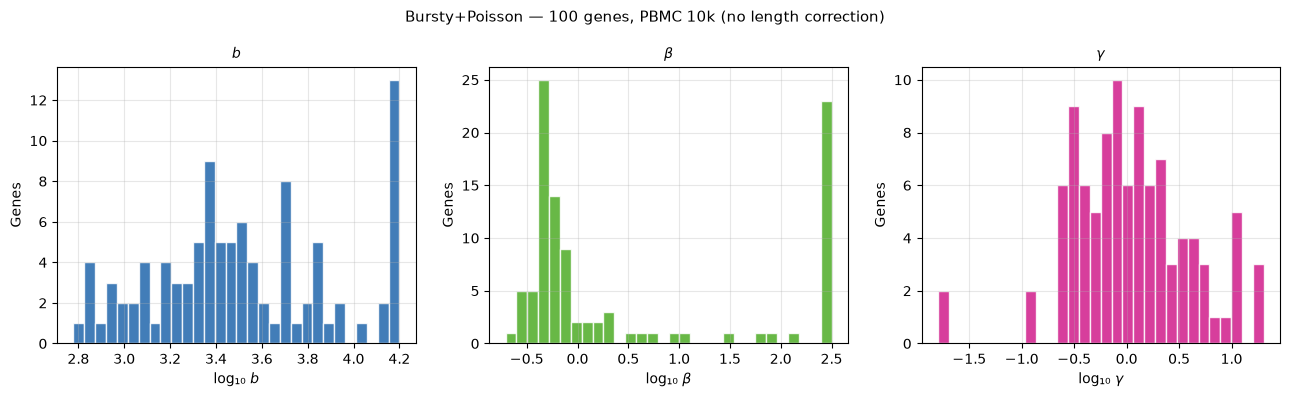

In [8]:
colors = ['#2166ac', '#4dac26', '#d01c8b']
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, pname, color in zip(axes, param_names, colors):
    ax.hist(res.var[pname].values, bins=30, color=color, alpha=0.85, edgecolor='white')
    ax.set_xlabel(f'log₁₀ {pname}', fontsize=10)
    ax.set_ylabel('Genes', fontsize=10)
    ax.set_title(pname, fontsize=10)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Bursty+Poisson — {N_GENES} genes, PBMC 10k (no length correction)', fontsize=11)
plt.tight_layout()
plt.show()

---
## Part 2 — Rust pipeline with gene length correction

When the sequencing model is `Poisson`, each gene's capture efficiency depends on
its length: longer pre-mRNAs produce more reads per molecule.  The `use_lengths`
parameter controls which sampling channels receive the per-gene log-length offset:

| Value | Effect |
|-------|--------|
| `None` | No length correction (genome-wide sampling rate) |
| `"unspliced"` | Add `log₁₀(gene_length)` to the unspliced channel |
| `"spliced"` | Add `log₁₀(gene_length)` to the spliced channel |
| `"both"` | Add `log₁₀(gene_length)` to both channels |

Here we use `use_lengths="unspliced"`, shifting only the unspliced channel by
`log₁₀(gene_length_bp)`, separating burst frequency from the length-driven
capture rate.

Gene lengths are expected in `adata.var['log_lengths']` (log₁₀ values, in bp).
In a real workflow these come from a GTF annotation via
`extract_data(..., transcriptome_filepath='path/to/annotation.gtf')`.  Here we
simulate a realistic log-normal distribution to keep the demo self-contained.

### Step 1 — Add gene lengths to the subsetted AnnData

In [9]:
adata_sub = adata[:, GENE_NAMES].copy()

# Simulate log10(gene_length_bp) — centred on ~60 kb, std ~0.35.
# Replace with real lengths from your annotation in production:
#   adata_sub.var['log_lengths'] = np.log10(gtf_lengths_df.loc[GENE_NAMES, 'length'])
rng = np.random.default_rng(42)
adata_sub.var['log_lengths'] = rng.normal(loc=4.78, scale=0.35, size=len(GENE_NAMES))

log_l = adata_sub.var['log_lengths'].values
print(f'log_lengths range: [{log_l.min():.2f}, {log_l.max():.2f}]')
print(f'Gene length range: [{10**log_l.min():.0f} bp, {10**log_l.max():.0f} bp]')

log_lengths range: [4.10, 5.53]
Gene length range: [12507 bp, 338514 bp]


### Step 2 — Build SearchData from AnnData

When `adata.var['log_lengths']` is present, `searchdata_from_adata` stores the
values in the Rust `SearchData.gene_log_lengths` field.  The Rust optimizer reads
them inside the rayon loop to add the per-gene length offset to the sampling-rate
grid point — no per-gene Python round-trip.

In [10]:
import monod.extract_data as _ed

# extract_data filters genes and computes unique histograms / truncation limits.
# Passing an AnnData directly (instead of a filepath) is supported.
adata_extracted = _ed.extract_data(
    adata_sub,
    MODEL,
    dataset_name='pbmc_lengths_demo',
    modality_name_dict={'unspliced': 'unspliced', 'spliced': 'spliced'},
    hist_type='unique',
    genes_to_fit=GENE_NAMES,
    viz=False,
)

sd_len = searchdata_from_adata(adata_extracted)

print(f'gene_log_lengths present: {sd_len.gene_log_lengths is not None}')
print(f'Genes: {sd_len.n_genes}  Cells: {sd_len.n_cells}')

gene_log_lengths present: True
Genes: 100  Cells: 10997


### Step 3 — Run inference with `use_lengths=True`

In [11]:
ip_len = InferenceParameters(
    'pbmc_rusty_lengths',
    MODEL,
    use_lengths="unspliced",   # adds log10(gene_length) to the unspliced sampling parameter
    gradient_params=GRADIENT_PARAMS,
    gridsize=GRIDSIZE,
    save=False,
)

t0 = time.perf_counter()
result_len = ip_len.fit_all_grid_points(sd_len, num_cores=1, save=False)
result_len.find_sampling_optimum()
print(f'Inference (with lengths): {(time.perf_counter()-t0)*1e3:.0f} ms')

params_len = result_len.phys_optimum
klds_len   = result_len.klds.min(axis=0)
print(f'KLD range: [{klds_len.min():.4f}, {klds_len.max():.4f}]')

Grid scan:   0%|          | 0/12 [00:00<?, ?it/s]

Grid scan:   8%|▊         | 1/12 [00:01<00:17,  1.55s/it]

Grid scan:  17%|█▋        | 2/12 [00:02<00:11,  1.11s/it]

Grid scan:  25%|██▌       | 3/12 [00:03<00:09,  1.01s/it]

Grid scan:  33%|███▎      | 4/12 [00:03<00:06,  1.22it/s]

...

Grid scan:  83%|████████▎ | 10/12 [00:10<00:02,  1.06s/it]

Grid scan:  92%|█████████▏| 11/12 [00:10<00:00,  1.01it/s]

Grid scan: 100%|██████████| 12/12 [00:11<00:00,  1.17it/s]

Grid scan: 100%|██████████| 12/12 [00:11<00:00,  1.05it/s]

Inference (with lengths): 11427 ms
KLD range: [0.0069, 0.4755]


### Step 4 — Save annotated result

In [12]:
RESULT_LEN_PATH = '/tmp/pbmc_rusty_lengths_result.h5ad'

for i, pname in enumerate(param_names):
    adata_extracted.var[pname] = params_len[:, i]
adata_extracted.var['kld'] = klds_len

adata_extracted.write_h5ad(RESULT_LEN_PATH)
print(f'Saved to {RESULT_LEN_PATH}')

res_len = ad.read_h5ad(RESULT_LEN_PATH)
print(res_len.var[param_names + ['kld', 'log_lengths']].head(10))

Saved to /tmp/pbmc_rusty_lengths_result.h5ad
            $b$   $\beta$  $\gamma$       kld  log_lengths
35335  1.698829  2.500000 -0.466495  0.101563     4.886651
35341  1.533005  2.500000 -0.602083  0.058225     4.416006
35337  1.419576  2.500000 -0.598694  0.070686     5.042658
35340  1.318879  2.500000 -0.659480  0.051101     5.109198
1426   2.732514  1.880751  0.765843  0.390358     4.097138
6145   1.417587  2.500000 -0.490853  0.035167     4.324237
35329  1.169140  2.500000 -0.672697  0.023195     4.824744
8919   1.423976  0.706125 -0.417282  0.055573     4.669315
36028  1.518618  1.666273 -0.321974  0.071168     4.774120
35331  1.195074  2.500000 -0.624513  0.036748     4.481435


### Step 5 — Compare parameters with and without length correction

The burst frequency `b` is the parameter most sensitive to length correction:
without it, length-driven differences in capture rate can be partially absorbed
into `b`, inflating burst frequency estimates for longer genes.

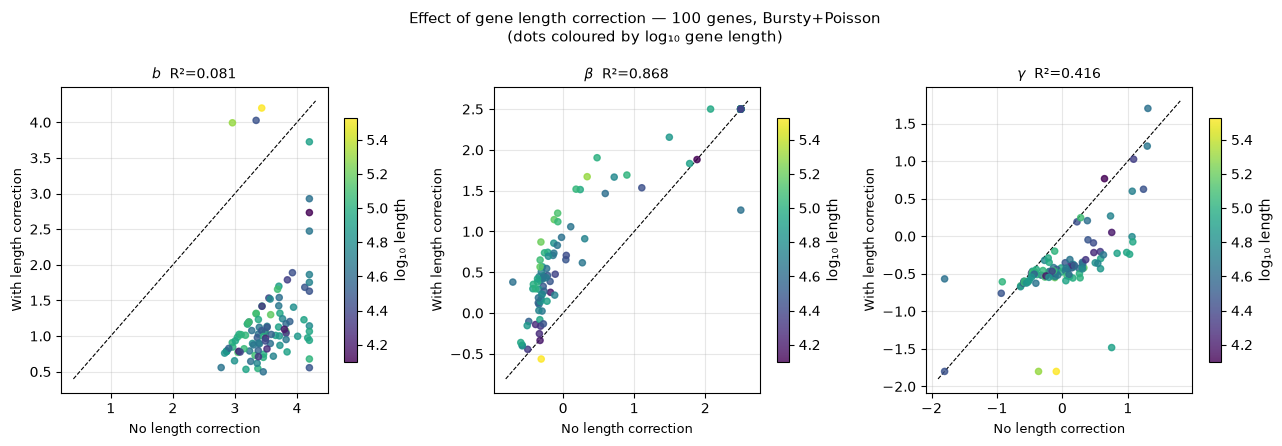

In [13]:
# Align on common genes (both subsets should be identical here).
common = list(res.var_names)
p_base = res.var.loc[common, param_names].values
p_len  = res_len.var.loc[common, param_names].values
ll     = res_len.var.loc[common, 'log_lengths'].values

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

for ax, pname, color in zip(axes, param_names, colors):
    pi = param_names.index(pname)
    xv, yv = p_base[:, pi], p_len[:, pi]
    sc = ax.scatter(xv, yv, c=ll, cmap='viridis', s=20, alpha=0.8, zorder=3)
    lo = min(xv.min(), yv.min()) - 0.1
    hi = max(xv.max(), yv.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    r2 = float(np.corrcoef(xv, yv)[0, 1] ** 2)
    ax.set_xlabel('No length correction', fontsize=9)
    ax.set_ylabel('With length correction', fontsize=9)
    ax.set_title(f'{pname}  R²={r2:.3f}', fontsize=10)
    plt.colorbar(sc, ax=ax, label='log₁₀ length', shrink=0.8)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    f'Effect of gene length correction — {N_GENES} genes, Bursty+Poisson\n'
    f'(dots coloured by log₁₀ gene length)',
    fontsize=11,
)
plt.tight_layout()
plt.show()